In [1]:
!pip install qiskit qiskit_aer --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00


### GRUPO
* Celso Lopes
* Fabrício Kolk Carvalho
* Gilberto Irajá Müller
* Nestor Diadamo Junior

In [32]:
import itertools, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.optimize import minimize

from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2, SamplerV2

from qiskit_aer.noise import NoiseModel, pauli_error


# backend   = AerSimulator()
# pm        = generate_preset_pass_manager(optimization_level=2, backend=backend)
# estimator = EstimatorV2()
# sampler   = SamplerV2()

In [2]:
import qiskit_aer, qiskit
print(qiskit.__version__)
print(qiskit_aer.__version__)

2.3.0
0.17.2


In [4]:
def get_quantum_noise_model(error_type='bitflip', p=0.05):
	if p == 0.0 or error_type is None:
		return None

	noise_model = NoiseModel()

	# Erros de 1 qubit
	if error_type == 'bitflip':
		err_1q = pauli_error([('X', p), ('I', 1 - p)])
	elif error_type == 'phaseflip':
		err_1q = pauli_error([('Z', p), ('I', 1 - p)])
	elif error_type == 'mixed':
			p_half = p / 2
			err_1q = pauli_error([('X', p_half), ('Z', p_half), ('I', 1 - p)])	
	else:
		raise ValueError("Tipo de erro inválido. Escolha 'bitflip' ou 'phaseflip'.")

	# Erros de 2 qubits (independentes)
	err_2q = err_1q.tensor(err_1q)

	# Aplicação do ruído nas portas lógicas do circuito QAOA com base nas portas geradas pós transpilação
	single_qubit_gates = ['rz', 'rx', 'h']
	two_qubit_gates = ['rzz']

	noise_model.add_all_qubit_quantum_error(err_1q, single_qubit_gates)
	noise_model.add_all_qubit_quantum_error(err_2q, two_qubit_gates)

	return noise_model

## Modelo

In [5]:
# ---------------- Problema direto ----------------

def build_M(h, offsets):
	# Matriz de tempos de transito, triangular inferior.
	# Raio i reflete na base da camada i. Angulo fixo por raio (raio reto):
	# tan(theta_i) = (offset_i/2) / H_i, com H_i = profundidade acumulada ate a base da camada i.
	m = len(h)
	H = np.cumsum(h)
	M = np.zeros((m, m))
	for i in range(m):
		theta = np.arctan((offsets[i] / 2.0) / H[i])
		for j in range(i + 1):
			M[i, j] = 2.0 * h[j] / np.cos(theta)
	return M

In [6]:
# ---------------- Modelo sintetico ----------------
M_LAYERS = 3          # numero de camadas
R_BITS   = 3          # bits por variavel real (R=3, como nos artigos)
N_QUBITS = M_LAYERS * R_BITS

h_true      = np.array([400.0, 350.0, 450.0])       # espessuras (m)
offsets     = np.array([600.0, 900.0, 1200.0])      # afastamentos fonte-receptor (m)
v_true      = np.array([1800.0, 2400.0, 3000.0])    # velocidades verdadeiras (m/s)
s_true      = 1.0 / v_true

M    = build_M(h_true, offsets)
t_obs = M @ s_true

print(f"Camadas: {M_LAYERS} | R = {R_BITS} bits | qubits = R x M = {N_QUBITS}")
print(f"(Albino et al. 2022 usaram 9, 12 e 18 qubits para 3, 4 e 6 camadas)\n")
print("Matriz M (m), triangular inferior:")
print(np.round(M, 1))
print(f"\nNumero de condicao de M: {np.linalg.cond(M):.2f}  (problema bem condicionado)")
print("\nTempos de transito observados (s):")
for i, tt in enumerate(t_obs):
	print(f"  t_{i+1} (reflexao na base da camada {i+1}): {tt:.6f}")

Camadas: 3 | R = 3 bits | qubits = R x M = 9
(Albino et al. 2022 usaram 9, 12 e 18 qubits para 3, 4 e 6 camadas)

Matriz M (m), triangular inferior:
[[1000.     0.     0. ]
 [ 933.   816.3    0. ]
 [ 894.4  782.6 1006.2]]

Numero de condicao de M: 3.99  (problema bem condicionado)

Tempos de transito observados (s):
  t_1 (reflexao na base da camada 1): 0.555556
  t_2 (reflexao na base da camada 2): 0.858446
  t_3 (reflexao na base da camada 3): 1.158407


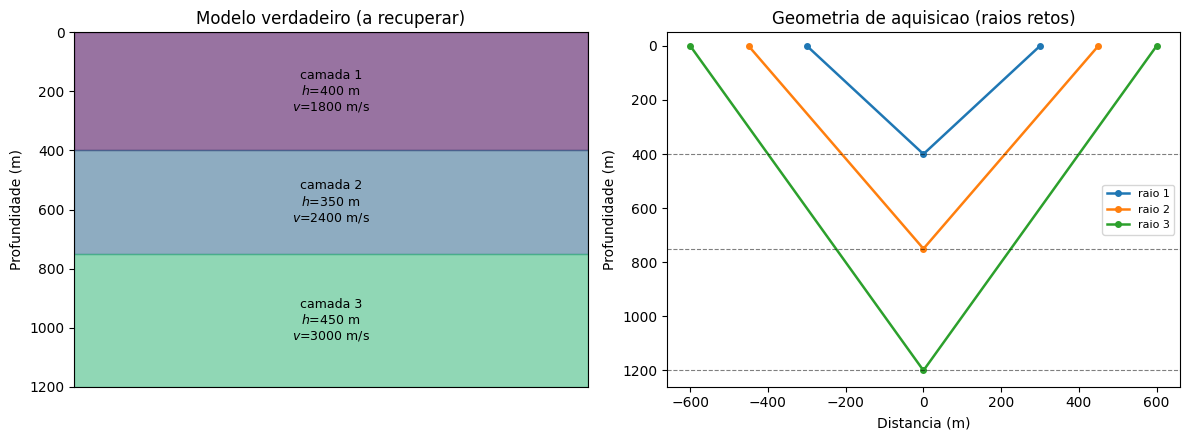

In [7]:
# ---------------- Visualizacao do modelo ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
z = np.concatenate([[0], np.cumsum(h_true)])
for j in range(M_LAYERS):
	ax.axhspan(z[j], z[j+1], color=plt.cm.viridis(j / M_LAYERS), alpha=.55)
	ax.text(0.5, (z[j] + z[j+1]) / 2,
			f"camada {j+1}\n$h$={h_true[j]:.0f} m\n$v$={v_true[j]:.0f} m/s",
			ha="center", va="center", fontsize=9)
ax.set_ylim(z[-1], 0); ax.set_xlim(0, 1); ax.set_xticks([])
ax.set_ylabel("Profundidade (m)"); ax.set_title("Modelo verdadeiro (a recuperar)")

ax = axes[1]
for i in range(M_LAYERS):
	Hi = np.cumsum(h_true)[i]
	xs = [-offsets[i]/2, 0, offsets[i]/2]
	ys = [0, Hi, 0]
	ax.plot(xs, ys, "-o", lw=1.8, ms=4, label=f"raio {i+1}")
for zz in z[1:]:
	ax.axhline(zz, color="k", lw=.8, ls="--", alpha=.5)
ax.set_ylim(z[-1] * 1.05, -50); ax.set_xlabel("Distancia (m)"); ax.set_ylabel("Profundidade (m)")
ax.set_title("Geometria de aquisicao (raios retos)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## QUBO

In [8]:
def expand_binary(M, R):
	# A[k, i*R+r] = M[k,i] * 2^(-r)  =>  A q = M x
	m, n = M.shape
	A = np.zeros((m, n * R))
	for i in range(n):
		for r in range(R):
			A[:, i * R + r] = M[:, i] * (2.0 ** (-r))
	return A


def qubo_from_ls(A, b):
	# QUBO de min ||A q - b||^2. Souza et al. eqs. (14)-(15).
	n = A.shape[1]
	Q = np.zeros((n, n))
	for i in range(n):
		Q[i, i] = np.sum(A[:, i] * (A[:, i] - 2.0 * b))
	for i in range(n):
		for j in range(i + 1, n):
			Q[i, j] = 2.0 * np.sum(A[:, i] * A[:, j])
	return Q, float(b @ b)


def q_to_x(q, n_real, R):
	# decodifica vetor binario em vetor real
	q = np.asarray(q, float).reshape(n_real, R)
	return q @ (2.0 ** (-np.arange(R)))


def qubo_energy(Q, off, q):
	q = np.asarray(q, float)
	return float(q @ Q @ q + off)


def brute_force(Q, off):
	# referencia exata (viavel apenas para n pequeno)
	n = Q.shape[0]
	best, bc = None, np.inf
	for bits in itertools.product([0, 1], repeat=n):
		c = qubo_energy(Q, off, bits)
		if c < bc:
			bc, best = c, list(bits)
	return best, bc

In [9]:
# ---------------- Construcao da primeira iteracao ----------------
s0_init = np.full(M_LAYERS, 1.0 / 2400.0)   # palpite: meio homogeneo a 2400 m/s
L_init  = 3.0e-4                            # limite de busca em lentidao

b = (t_obs + L_init * (M @ np.ones(M_LAYERS)) - M @ s0_init) / L_init
A = expand_binary(M, R_BITS)
Q, offset = qubo_from_ls(A, b)

print(f"A: {A.shape}   Q: {Q.shape}  ->  {Q.shape[0]} qubits")
dens = np.count_nonzero(np.triu(Q, 1)) / (Q.shape[0] * (Q.shape[0] - 1) / 2)
print(f"Densidade do grafo QUBO (fora da diagonal): {dens:.1%}")
print(f"\nQ (primeiras 5x5 entradas):\n{np.round(Q[:5,:5], 1)}")

A: (3, 9)   Q: (9, 9)  ->  9 qubits
Densidade do grafo QUBO (fora da diagonal): 100.0%

Q (primeiras 5x5 entradas):
[[-9366192.6  2670400.   1335200.   2923200.   1461600. ]
 [       0.  -5350696.3   667600.   1461600.    730800. ]
 [       0.         0.  -2842248.1   730800.    365400. ]
 [       0.         0.         0.  -6692933.3  1278900. ]
 [       0.         0.         0.         0.  -3666191.7]]


In [10]:
q_bf, e_bf = brute_force(Q, offset)
x_bf = q_to_x(q_bf, M_LAYERS, R_BITS)
s_bf = s0_init + L_init * (x_bf - 1.0)

print(f"q* (forca bruta) = {q_bf} energia {e_bf}")
print(f"x*               = {x_bf}")
print(f"\nApos 1 iteracao:")
print(f"  v recuperado = {np.round(1.0 / s_bf, 1)} m/s")
print(f"  v verdadeiro = {v_true} m/s")
err1 = np.abs(1.0 / s_bf - v_true) / v_true * 100
print(f"  erro relativo = {np.round(err1, 2)} %  (max {err1.max():.2f}%)")

q* (forca bruta) = [1, 1, 0, 1, 0, 0, 0, 1, 1] energia 6296.20198902674
x*               = [1.5  1.   0.75]

Apos 1 iteracao:
  v recuperado = [1764.7 2400.  2926.8] m/s
  v verdadeiro = [1800. 2400. 3000.] m/s
  erro relativo = [1.96 0.   2.44] %  (max 2.44%)


In [11]:
def qubo_to_ising(Q, off):
	# q_j = (1 - z_j)/2
	n = Q.shape[0]
	Qs = (Q + Q.T) / 2.0
	d  = np.diag(Qs).copy()
	O  = Qs - np.diag(d)
	h  = -d / 2.0
	J  = np.zeros((n, n))
	c  = off + d.sum() / 2.0
	for i in range(n):
		for j in range(n):
			if i == j:
				continue
			qq = O[i, j]
			c    += qq / 4.0
			h[i] -= qq / 4.0
			h[j] -= qq / 4.0
			J[i, j] += qq / 4.0
	return h, J, c


def ising_energy(h, J, c, z):
	z = np.asarray(z, float)
	return float(h @ z + z @ J @ z + c)


def ising_to_pauli(h, J, n, tol=1e-10):
	terms = []
	for i in range(n):
		if abs(h[i]) > tol:
			p = ["I"] * n; p[n - 1 - i] = "Z"
			terms.append(("".join(p), float(h[i])))
	for i in range(n):
		for j in range(i + 1, n):
			c = J[i, j] + J[j, i]
			if abs(c) > tol:
				p = ["I"] * n; p[n - 1 - i] = "Z"; p[n - 1 - j] = "Z"
				terms.append(("".join(p), float(c)))
	return SparsePauliOp.from_list(terms)

In [12]:
# ---------------- Verificacao numerica da equivalencia ----------------
alpha = np.abs(Q).max()                       # normalizacao
h_is, J_is, c_is = qubo_to_ising(Q / alpha, offset / alpha)
H_cost = ising_to_pauli(h_is, J_is, N_QUBITS)

err = 0.0
for bits in itertools.product([0, 1], repeat=N_QUBITS):
	z = [1 - 2 * bb for bb in bits]
	err = max(err, abs(qubo_energy(Q / alpha, offset / alpha, bits)
					   - ising_energy(h_is, J_is, c_is, z)))

print(f"Fator de normalizacao alpha = {alpha:.3e}")
print(f"Hamiltoniano: {len(H_cost)} termos de Pauli")
print(f"Erro maximo QUBO vs Ising sobre os {2**N_QUBITS} estados: {err:.2e}")
print("Transformacao exata." if err < 1e-8 else "ERRO na transformacao.")

Fator de normalizacao alpha = 9.366e+06
Hamiltoniano: 45 termos de Pauli
Erro maximo QUBO vs Ising sobre os 512 estados: 5.00e-16
Transformacao exata.


## QAOA

In [13]:
# Inserção do erro nos parâmetros error_type e p_error
def qaoa_solve(Q, off, reps=3, restarts=3, shots=4096, seed=0, maxiter=250,
			   return_details=False, error_type=None, p_error=0.0):
	# Ajuste para o modelo ruidoso
	noise_model = None
	if p_error > 0:
		noise_model = get_quantum_noise_model(error_type, p_error)

	backend   = AerSimulator(noise_model = noise_model) if noise_model else AerSimulator()
	pm        = generate_preset_pass_manager(optimization_level=2, backend=backend)

	estimator = EstimatorV2(
		options={
			"backend_options": {
				"noise_model": noise_model
			}
		}
	)

	sampler = SamplerV2(
		options={
			"backend_options": {
				"noise_model": noise_model
			}
		}
	)
	#estimator = EstimatorV2.from_backend(backend)
	#sampler   = SamplerV2.from_backend(backend)

	n = Q.shape[0]
	a = np.abs(Q).max()
	hh, JJ, cc = qubo_to_ising(Q / a, off / a)
	H = ising_to_pauli(hh, JJ, n)

	raw  = QAOAAnsatz(cost_operator=H, reps=reps)
	rawm = raw.copy(); rawm.measure_all()
	ans, ansm = pm.run(raw), pm.run(rawm)
	HL = H.apply_layout(ans.layout)           # remapeia o Hamiltoniano apos transpilacao

	rng = np.random.default_rng(seed)
	hist = []
	def energia(theta):
		val = float(estimator.run([(ans, HL, theta)]).result()[0].data.evs)
		hist.append(val)
		return val

	best = None
	for _ in range(restarts):
		r = minimize(energia, rng.uniform(0, np.pi, ans.num_parameters),
					 method="COBYLA", options={"maxiter": maxiter})
		if best is None or r.fun < best.fun:
			best = r

	counts = sampler.run([(ansm, best.x)], shots=shots).result()[0].data.meas.get_counts()

	# melhor entre os shots
	bq, be = None, np.inf
	for sbits, ct in counts.items():
		q = [int(z) for z in sbits[::-1]]      # little-endian -> ordem das variaveis
		e = qubo_energy(Q, off, q)
		if e < be:
			be, bq = e, q

	if return_details:
		modo = max(counts.items(), key=lambda kv: kv[1])
		return bq, be, counts, [int(z) for z in modo[0][::-1]], hist, ans
	return bq, be

In [14]:
# ---------------- Circuito ----------------
backend   = AerSimulator()
pm        = generate_preset_pass_manager(optimization_level=2, backend=backend)
estimator = EstimatorV2.from_backend(backend)
sampler   = SamplerV2.from_backend(backend)

_raw = QAOAAnsatz(cost_operator=H_cost, reps=3)
_tr  = pm.run(_raw)
print(f"Qubits: {_raw.num_qubits} | p = 3 -> {_raw.num_parameters} parametros")
print(f"Profundidade transpilada: {_tr.depth()}")
print(f"Portas: {dict(_tr.count_ops())}")

Qubits: 9 | p = 3 -> 6 parametros
Profundidade transpilada: 40
Portas: {'rzz': 108, 'rz': 27, 'rx': 27, 'h': 9}


# PLANEJAMENTO DOS EXPERIMENTOS 
* Definimos cenários sem erro, com bit-flip, com phase-flip e misto (X e Z) com 10%, 15% e 20% nos cenários com erro
* Reduzimos o número de shots no Sampler (512) e iterações no COBYLA (50) para que o efeito do ruído seja percebido e que alcance a solução ideal (v_true)
* Após os experimentos, montamos uma tabela com os erros máximos por iteração
* Por fim, plotamos os gráficos para cada experimento com a convergência do perfil de velocidade e da convergência do erro

In [43]:
experiments = [
	{ 'error_type': None, 'p_error': 0.0 },
	{ 'error_type': 'bitflip', 'p_error': 0.10 },
	{ 'error_type': 'bitflip', 'p_error': 0.15 },
	{ 'error_type': 'bitflip', 'p_error': 0.20 },
	{ 'error_type': 'phaseflip', 'p_error': 0.10 },
	{ 'error_type': 'phaseflip', 'p_error': 0.15 },
	{ 'error_type': 'phaseflip', 'p_error': 0.20 },
	{ 'error_type': 'mixed', 'p_error': 0.10 },
	{ 'error_type': 'mixed', 'p_error': 0.15 },
	{ 'error_type': 'mixed', 'p_error': 0.20 },
]
N_ITER = 8

hist_v_total = []
hist_err_total = []
match_total = []

for exp in experiments:
	print(f"\n*** CENÁRIO: error_type = {exp['error_type']} p_error = {exp['p_error']}")
	t0 = time.time()
	hist_v, hist_err, match = [1.0 / s0_init.copy()], [], []
	s_cur, L_cur = s0_init.copy(), L_init
	for it in range(1, N_ITER + 1):
		t0_iter = time.time()
		b_k = (t_obs + L_cur * (M @ np.ones(M_LAYERS)) - M @ s_cur) / L_cur
		Q_k, off_k = qubo_from_ls(A, b_k)

		q_ref, _ = brute_force(Q_k, off_k)                      # auditoria
		q_k, _   = qaoa_solve(Q_k, off_k, reps=3, restarts=3, seed=10 * it, shots=512, maxiter=50, error_type=exp['error_type'], p_error=exp['p_error'])

		s_cur = s_cur + L_cur * (q_to_x(q_k, M_LAYERS, R_BITS) - 1.0)
		L_cur *= 0.25

		e = np.abs(1.0 / s_cur - v_true) / v_true * 100
		hist_v.append(1.0 / s_cur); hist_err.append(e.max()); match.append(q_k == q_ref)
		v_formatados = ", ".join(f"{x:7.1f}" for x in np.round(1.0/s_cur, 1))
		print(f"it {it}: v = [{v_formatados}] m/s | erro max = {e.max():7.4f}% | "
			  f"QAOA {'==' if q_k == q_ref else '!='} forca bruta (error_type = {exp['error_type']} p_error = {exp['p_error']})  time {time.time() - t0_iter:.1f}")

	hist_v_total.append(hist_v)
	hist_err_total.append(hist_err)
	match_total.append(match)

	print(f"\nTempo total: {time.time() - t0:.1f} s")
	print(f"QAOA igualou a forca bruta em {sum(match)}/{N_ITER} iteracoes.")
	print(f"\nVelocidade final     : {np.round(1.0/s_cur, 2)} m/s")
	print(f"Velocidade verdadeira: {v_true} m/s")
	print(f"Erro relativo final  : {hist_err[-1]:.4f} %")


*** CENÁRIO: error_type = None p_error = 0.0
it 1: v = [ 1764.7,  2400.0,  2926.8] m/s | erro max =  2.4390% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.8
it 2: v = [ 1825.1,  2400.0,  2926.8] m/s | erro max =  2.4390% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.3
it 3: v = [ 1794.4,  2400.0,  3009.4] m/s | erro max =  0.3135% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.1
it 4: v = [ 1798.2,  2406.8,  2998.8] m/s | erro max =  0.2820% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 3.8
it 5: v = [ 1800.1,  2401.7,  2998.8] m/s | erro max =  0.0704% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.2
it 6: v = [ 1799.8,  2400.4,  3000.1] m/s | erro max =  0.0176% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.0
it 7: v = [ 1800.0,  2400.1,  3000.0] m/s | erro max =  0.0044% | QAOA == forca bruta (error_type = None p_error = 0.0)  time 4.2
it 8: v = [ 1800.0,  2400.0,  3000.0] m/s | 

In [41]:
data = []
for i, exp in enumerate(experiments):
    tipo = str(exp['error_type']) if exp['error_type'] is not None else 'Ideal'
    p = exp['p_error']
    
    row = {
        'Tipo de Erro': tipo,
        'Prob. (p_error)': p,
    }
    
    for it_idx, err_val in enumerate(hist_err_total[i], start=1):
        row[f'Erro It {it_idx} (%)'] = round(err_val, 2)
        
    # Coluna com a quantidade de vezes que atingiu o ótimo
    row['Ótimo (Match/N_ITER)'] = f"{sum(match_total[i])}/{N_ITER}"
    
    data.append(row)

df_results = pd.DataFrame(data)
print("\n--- TABELA COMPARATIVA DE ERROS POR ITERAÇÃO ---")
#print(df_results.to_markdown(index=False))
df_results


--- TABELA COMPARATIVA DE ERROS POR ITERAÇÃO ---


,Tipo de Erro,Prob. (p),Erro It 1 (%),Erro It 2 (%),Erro It 3 (%),Erro It 4 (%),Erro It 5 (%),Erro It 6 (%),Erro It 7 (%),Erro It 8 (%),Ótimo (Match/N_ITER)
0,Ideal,0.00,2.44,9.89,7.51,6.30,6.14,6.06,6.04,6.04,1/8
1,bitflip,0.10,33.33,27.59,27.59,26.57,26.32,26.34,26.32,26.32,0/8
2,bitflip,0.15,117.39,98.02,85.61,83.70,83.22,83.05,83.00,82.99,0/8
3,bitflip,0.20,32.20,23.44,20.00,19.09,18.97,18.95,18.93,18.93,1/8
4,phaseflip,0.10,21.95,12.09,9.86,8.70,8.92,8.90,8.90,8.90,1/8
5,phaseflip,0.15,73.91,73.91,62.03,59.30,58.86,58.75,58.73,58.73,0/8
6,phaseflip,0.20,32.20,26.61,25.06,24.26,24.06,24.03,24.02,24.02,0/8
7,mixed,0.10,73.91,34.45,31.96,30.75,30.30,30.26,30.23,30.23,2/8
8,mixed,0.15,56.25,29.03,25.39,24.95,24.62,24.60,24.60,24.60,0/8
9,mixed,0.20,117.39,68.07,59.05,57.64,57.29,57.33,57.36,57.36,0/8


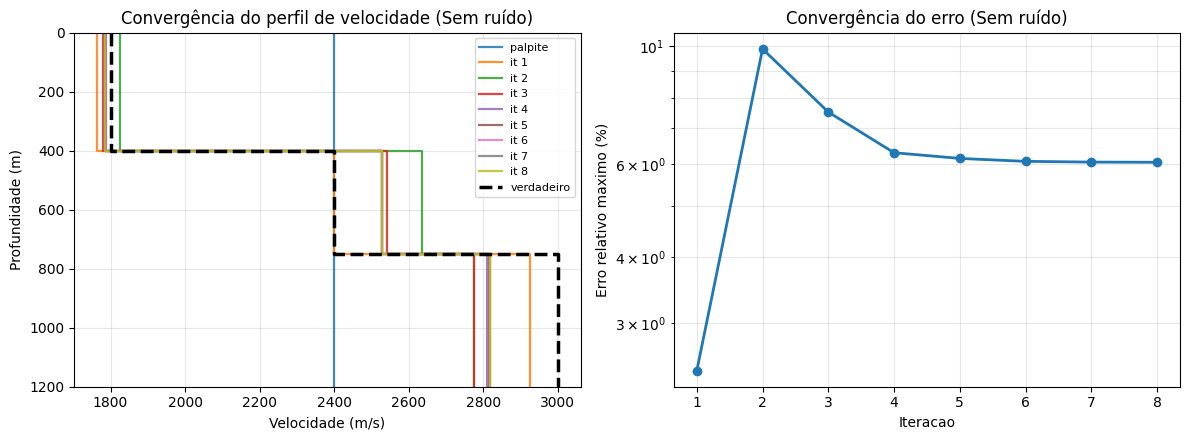

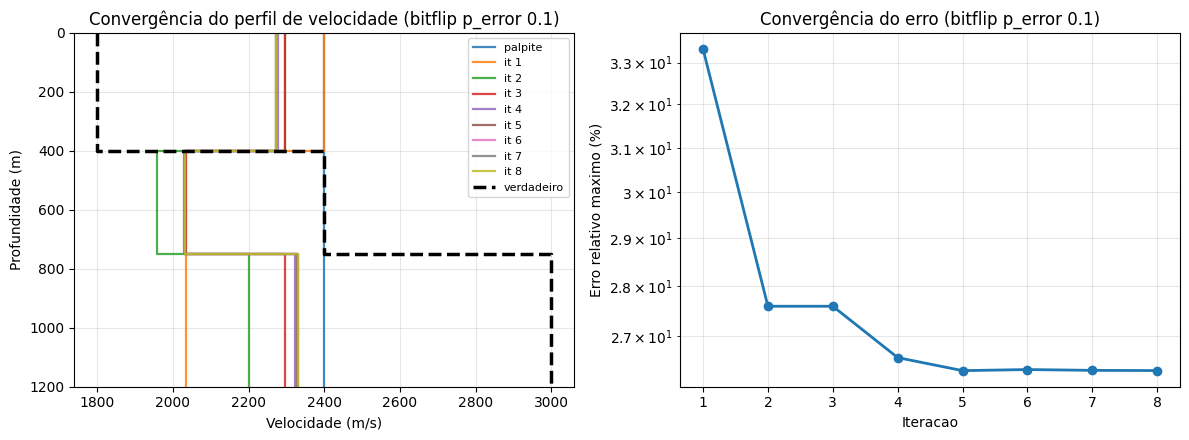

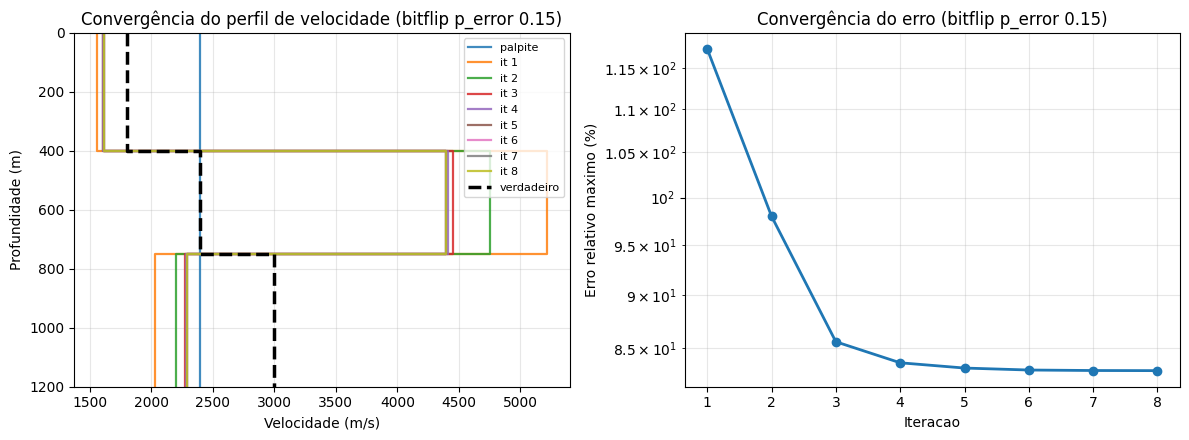

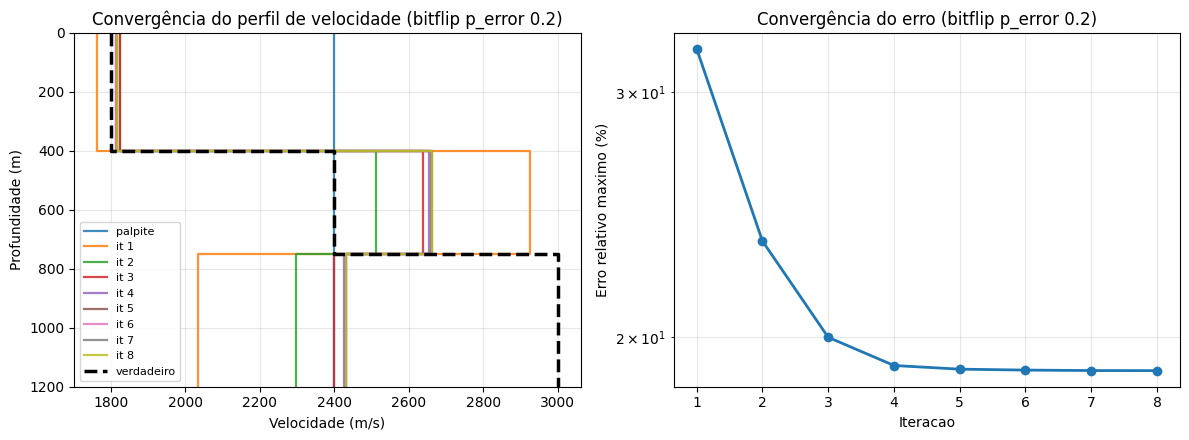

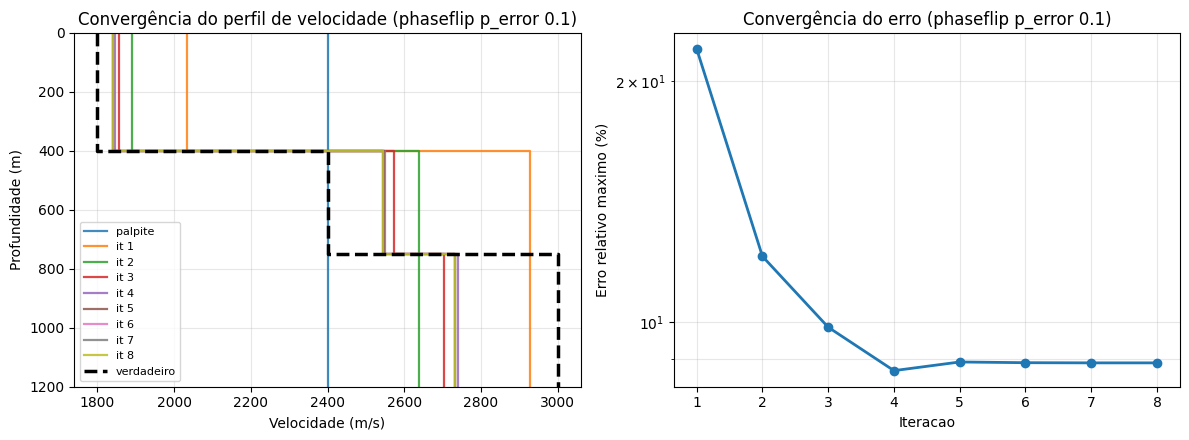

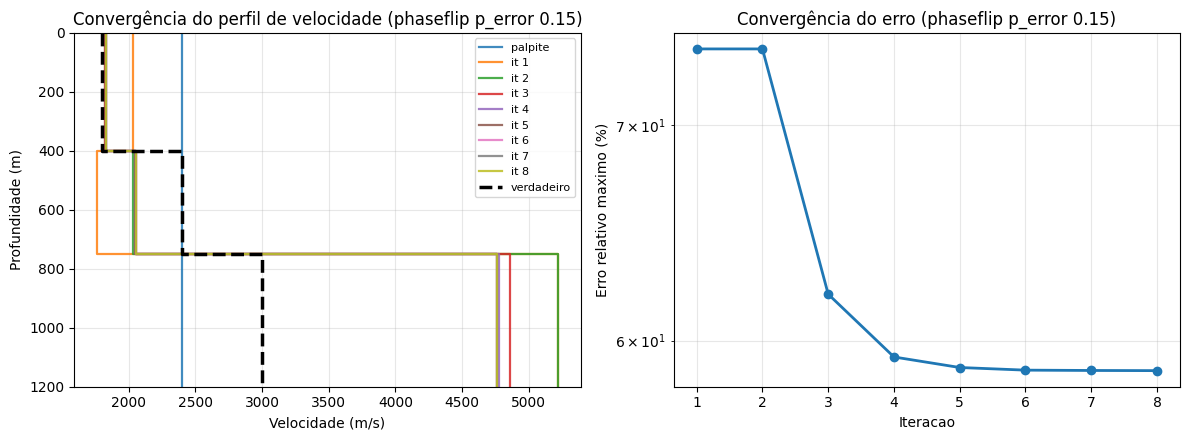

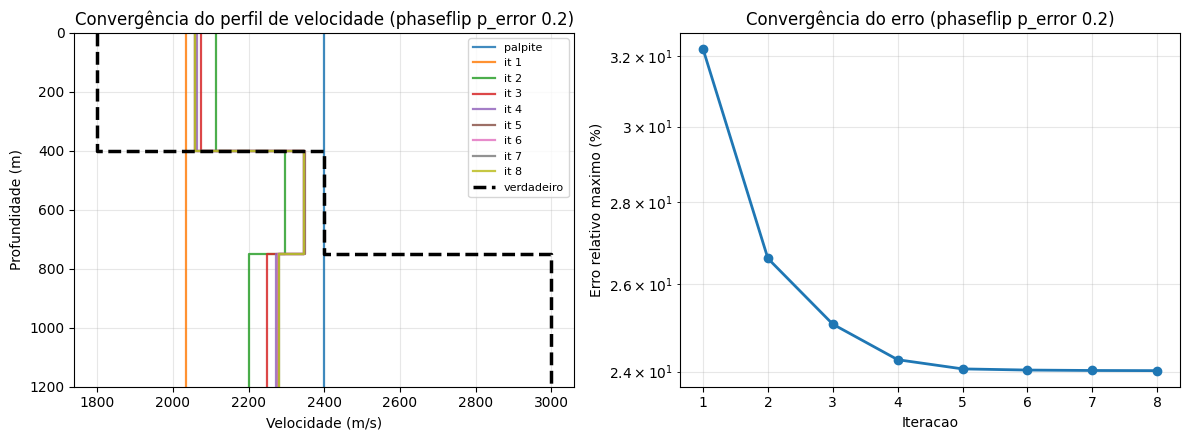

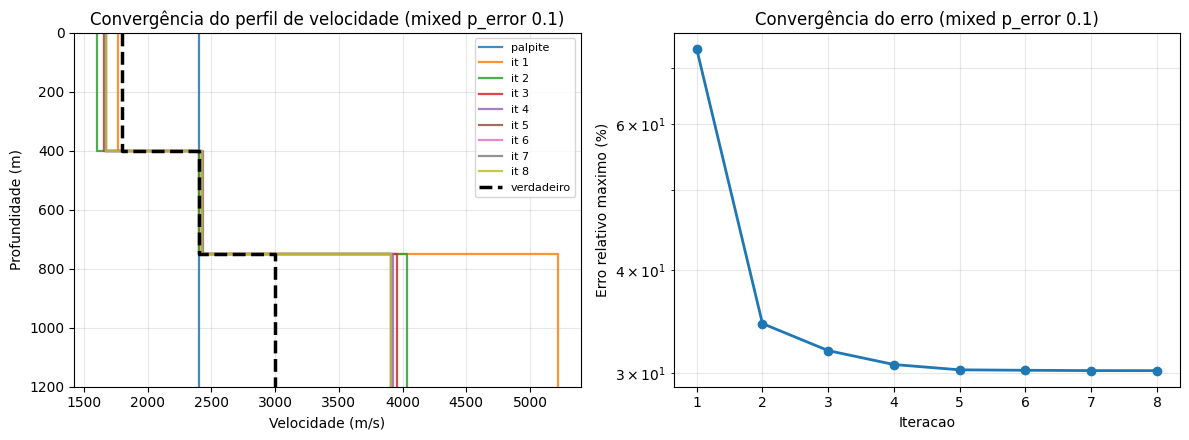

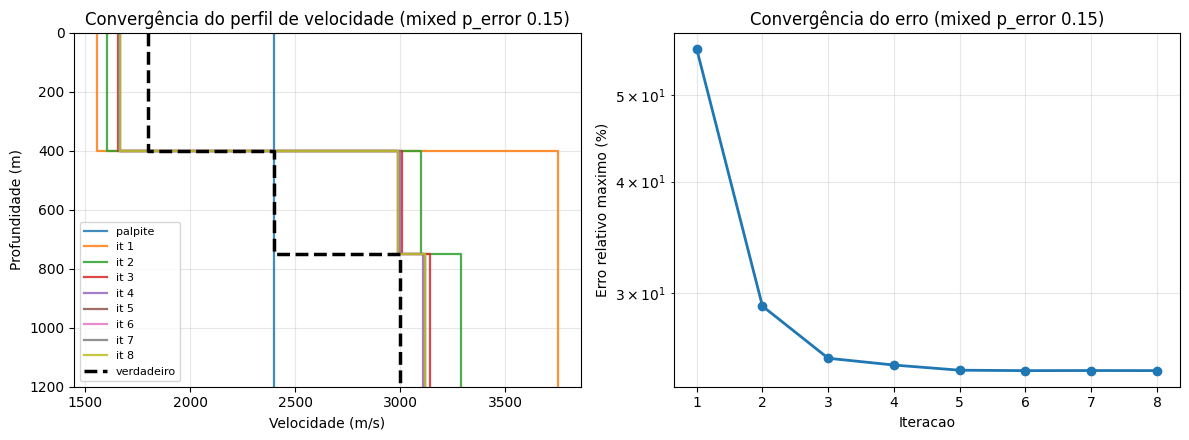

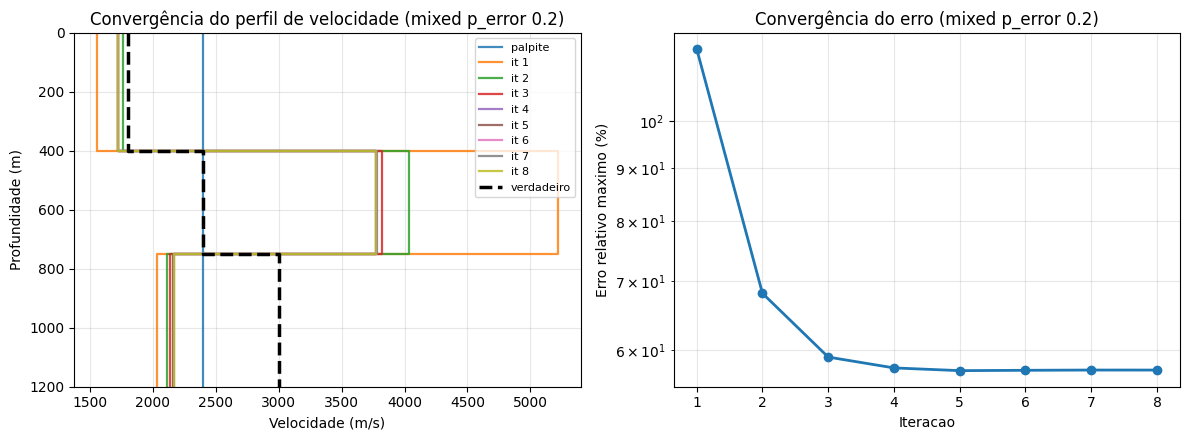

In [42]:
def plot(hist_v, hist_err, title):
	hist_v = np.array(hist_v)
	fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

	ax = axes[0]
	zc = np.concatenate([[0], np.cumsum(h_true)])
	def stairs(v):
		xs, ys = [], []
		for j in range(len(v)):
			xs += [v[j], v[j]]; ys += [zc[j], zc[j+1]]
		return xs, ys
	#for k in [0, 1, 2, 3, 4, 5, 6, 7, len(hist_v) - 1]:
	for k in range(len(hist_v)):
		xs, ys = stairs(hist_v[k])
		ax.plot(xs, ys, lw=1.6, alpha=.85, label=f"it {k}" if k else "palpite")
	xs, ys = stairs(v_true)
	ax.plot(xs, ys, "k--", lw=2.5, label="verdadeiro")
	ax.set_ylim(zc[-1], 0); ax.set_xlabel("Velocidade (m/s)"); ax.set_ylabel("Profundidade (m)")
	ax.set_title(f"Convergência do perfil de velocidade ({title})"); ax.legend(fontsize=8); ax.grid(alpha=.3)

	# erro vs iteracao
	ax = axes[1]
	ax.semilogy(range(1, N_ITER + 1), hist_err, "o-", lw=2)
	ax.set_xlabel("Iteracao"); ax.set_ylabel("Erro relativo maximo (%)")
	ax.set_title(f"Convergência do erro ({title})"); ax.grid(alpha=.3, which="both")
	plt.tight_layout(); plt.show()

# Plotar gráfico
for i, exp in enumerate(experiments):
	plot(hist_v_total[i], hist_err_total[i], title=f"{exp['error_type']} p_error {exp['p_error']}" if exp['p_error'] > 0 else 'Sem ruído')